# The impact substitute: when and where teams used it

**The question, given the exploration.** From 2023 each side may replace one named player during the match. The exploration, using Cricsheet's replacement records, showed the substitute deployed in the first innings far more often in 2024 (43 of 137 against 26 of 139) and, on the face of it, more often at the death (37 against 27). The first read is a change in strategy (using the sub proactively rather than switching for the second discipline); the second looked like a change in timing. Both need testing with the match as the unit, and the second needs untangling from the first: if more subs come in the first innings, and first-innings subs tend to come late, the death share can rise with no change in timing at all.

**What this notebook does.**
1. Counts and the phase mix of deployments per innings and season.
2. The pooled death-entry share change as it first read, then an exact split of it into an innings-mix component (what the reallocation alone would do to the pooled share, with timing held fixed) and a within-innings timing component. The two add up to the pooled change on every resample.
3. The second-innings share and the death-entry share within each innings as season contrasts with intervals.
4. An equivalence verdict for each, against a pre-stated smallest effect of ten percentage points: the direction is a finding only when the interval excludes zero; otherwise the row is directional with its minimum detectable effect, or equivalent to zero.

**How to read this notebook.** Shares are fractions of deployments; the tables give them in points where the verdicts are. The resampling unit is the match (two subs in one match respond to the same game state), and a match with no deployment in an innings keeps its place with zero counts. Impact-player events only; the one concussion substitute is an injury replacement, not a choice, and is excluded.

**Numbers in the text.** Quoted from the run of 9 September 2026 under the seed in `config.toml`. Code lives in `scripts/impact_substitute/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from impact_substitute import deployment_shift as ds

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "impact_substitute"
SEED = settings.seed(ANALYSIS)
N_ITER = settings.n_resamples
PRODUCER = "impact_substitute.ipynb"
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000


## Data

The impact-player table (`data/impact_player_table.parquet`, built in `exploration.ipynb` from the Cricsheet archive), impact-player events only. Match ids align with the ball-by-ball frame; players were reconciled by name.

In [2]:
events = ds.load_impact_events(settings.data_path("impact_player_table"))
print(f"events={len(events)}  matches={events['match_id'].nunique()}  seasons={sorted(events['season'].unique())}")
EXTRA = {"n_resamples": N_ITER, "sesoi_points": settings.section("sesoi")["impact_share_points"]}

events=276  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Counts and phase mix

Events and matches per season and innings, and the deployment phase within each innings. Found: 139 and 137 events over 74 and 71 matches; first-innings deployments 26 and 43; within the first innings about 70% of deployments arrive at the death in both seasons, within the second innings about 7%. That last pair is the crux: timing inside an innings looks the same in both seasons, and it is the innings mix that moved.

In [3]:
analysis = ds.run_deployment_analysis(events, settings, SEED, n_iter=N_ITER)
results_io.write_table(analysis["counts"], settings, ANALYSIS, "deployment_counts", SEED, PRODUCER, EXTRA)
results_io.write_table(analysis["phase_mix"], settings, ANALYSIS, "deployment_phase_mix", SEED, PRODUCER, EXTRA)
display(analysis["counts"])
analysis["phase_mix"].round(3)

,season,innings,events,matches
0,2023,1,26,24
1,2023,2,113,69
2,2024,1,43,35
3,2024,2,94,58


,innings,season,deploy_phase,events,share
0,1,2023,death,18,0.692
1,1,2023,middle,8,0.308
2,1,2024,death,31,0.721
3,1,2024,middle,10,0.233
4,1,2024,powerplay,2,0.047
5,2,2023,death,9,0.080
6,2,2023,middle,21,0.186
7,2,2023,powerplay,83,0.735
8,2,2024,death,6,0.064
9,2,2024,middle,19,0.202


## The pooled death-entry change, split into mix and timing

`identity_max_abs_error` is the largest gap between the pooled change and the sum of its two components across all resamples; it should be at floating-point precision.

In [4]:
decomposition = analysis["decomposition"]
results_io.write_table(decomposition, settings, ANALYSIS, "death_entry_decomposition", SEED, PRODUCER,
                       {**EXTRA, "identity_max_abs_error": decomposition.attrs["identity_max_abs_error"]})
print("identity_max_abs_error:", decomposition.attrs["identity_max_abs_error"])
decomposition.round(4)

identity_max_abs_error: 9.71445146547012e-17


,component,estimate,ci_low,ci_high,p_positive,interval_method
0,pooled_death_entry_share_change,0.0758,-0.0208,0.1680,0.9397,percentile
1,innings_mix_component,0.0805,0.0131,0.1516,0.9906,percentile
2,within_innings_timing_component,-0.0047,-0.0796,0.0727,0.4450,percentile


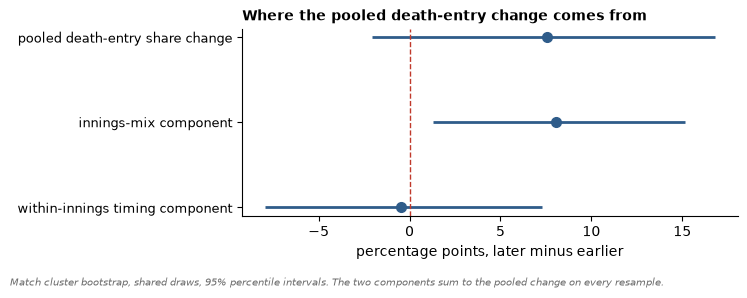

In [5]:
fig = ds.plot_decomposition(decomposition, settings.interval_level)
results_io.write_figure(fig, settings, ANALYSIS, "death_entry_decomposition", SEED, PRODUCER)
plt.show()

The pooled death-entry share rose 7.6 points (interval −2 to +17). Of that, the innings-mix component is +8.1 points (interval +1.2 to +15.5) and the within-innings timing component −0.5 points (interval −7.8 to +7.0). The apparent shift toward death-overs entry is entirely the reallocation of subs to the first innings, where they have always tended to enter late; there is no change in when a sub enters within an innings. What first read as a timing change is a composition effect, and the decomposition shows it exactly.

## Reallocation and within-innings timing as season contrasts

Shares are fractions. `ci_low` and `ci_high` are the primary interval (`interval_method`); the BCa interval and the closed-form cluster standard error are alongside.

In [6]:
themes = analysis["themes"]
results_io.write_table(themes, settings, ANALYSIS, "deployment_themes", SEED, PRODUCER, EXTRA)
themes[["theme", "share_earlier", "share_later", "estimate", "ci_low", "ci_high", "interval_method",
        "bca_low", "bca_high", "se_linearized", "resampling_stable", "n_matches_earlier", "n_matches_later"]].round(4)

,theme,share_earlier,share_later,estimate,ci_low,ci_high,interval_method,bca_low,bca_high,se_linearized,resampling_stable,n_matches_earlier,n_matches_later
0,pooled_death_entry_share_diff,0.1942,0.2701,0.0758,-0.0189,0.1720,bootstrap_t,-0.0204,0.1686,0.0484,False,74,71
1,second_innings_share_diff,0.8129,0.6861,-0.1268,-0.2347,-0.0221,bootstrap_t,-0.2319,-0.0207,0.0547,True,74,71
2,death_entry_share_diff_innings_1,0.6923,0.7209,0.0286,-0.2021,0.3014,bootstrap_t,-0.1865,0.2849,0.1180,False,74,71
3,death_entry_share_diff_innings_2,0.0796,0.0638,-0.0158,-0.0840,0.0561,bootstrap_t,-0.0833,0.0539,0.0345,False,74,71


## Equivalence verdicts

Percentage points. `direction_status` is the reporting rule: a direction is a finding only under `rejects_null`; `inconclusive` rows are directional with their minimum detectable effect stated; `equivalent_to_zero` rows are tested nulls against the ten-point SESOI.

In [7]:
verdicts = analysis["verdicts"]
results_io.write_table(verdicts, settings, ANALYSIS, "deployment_equivalence_verdicts", SEED, PRODUCER, EXTRA)
verdicts[["channel", "direction", "estimate", "ci90_low", "ci90_high", "ci95_low", "ci95_high", "se", "sesoi",
          "mde_80pct_power", "verdict", "direction_status"]].round(2)

,channel,direction,estimate,ci90_low,ci90_high,ci95_low,ci95_high,se,sesoi,mde_80pct_power,verdict,direction_status
0,second_innings_share_diff,later lower,-12.68,-21.77,-3.92,-23.47,-2.21,5.47,10.0,15.31,rejects_null,established direction
1,death_entry_share_diff_innings_1,later higher,2.86,-16.38,25.10,-20.21,30.14,11.80,10.0,33.04,inconclusive,directional; MDE stated
2,death_entry_share_diff_innings_2,later lower,-1.58,-7.20,4.38,-8.40,5.61,3.45,10.0,9.67,equivalent_to_zero,equivalent to zero


The second-innings share fell from 81% to 69%: −12.7 points, interval −23.7 to −2.0, rejects the null, so the reallocation to the first innings is an established finding. Within the second innings the death-entry share moved −1.6 points with a 90% interval of −7 to +4, inside the ten-point band: equivalent to zero. Within the first innings it moved +2.9 points on 26 and 43 events, inconclusive with a minimum detectable effect of 33 points; nothing could have been detected there. 

Teams moved the impact substitute into the first innings in 2024; when they used it within an innings did not change, and the earlier impression of more death-overs deployments was the reallocation showing through the pooled numbers.